# Knowledge graphs

Generate PNG images and interactive HTML views of the **complete knowledge graph** of each dataset,
including isolated nodes. Complete views preserve every node and edge. An optional bounded subset provides
a smaller view for exploration.
Colors identify entity types. Reverse message-passing edges are drawn only once
with their forward relation; arrows are omitted for readability.

`SOURCE="raw"` uses each source's prepared item catalog with the shared sparsity
filter disabled, so every source-retained item is kept and the optional
whole-user/concept reductions are not applied. `SOURCE="cache"` uses the
processed catalog, which may be reduced. Neither mode changes data or caches
or loads text encoders.

Full graphs may take time and memory to lay out; dense regions can overlap in a
static image. PNG and self-contained HTML files are saved under `results/knowledge_graphs/`.

## Setup

Use the project's Python environment with `networkx` and `plotly` installed, and install
**Graphviz** so that `sfdp` is on PATH. Matplotlib is a project dependency.
For example, launch with `uv run --with networkx --with plotly --with jupyterlab jupyter lab`.

In [1]:
import os
import sys
from pathlib import Path

import pandas as pd
from IPython.display import HTML, display

ROOT = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "edurec").is_dir() and (path / "pyproject.toml").is_file()
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Open the notebook inside the EDuRec repository.")
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

pd.set_option("display.max_colwidth", 100)
print(f"Repository: {ROOT}")

Repository: /Users/i12almuf/Code/projects/EDuRec


In [2]:
import random
import shutil
import subprocess
from collections import deque
from dataclasses import dataclass
from html import escape
from typing import Literal

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import plotly.graph_objects as go
import torch
from matplotlib.collections import LineCollection
from torch_geometric.data import HeteroData

from edurec import settings
from edurec.datasets import DataConfig
from edurec.datasets.cache import ProcessedData
from edurec.datasets.graphs import build_knowledge_graph
from edurec.datasets.preprocessing.ids import encode_ids
from edurec.datasets.preprocessing.lists import normalize_lists
from edurec.datasets.preprocessing.reduction import clean_cols
from edurec.datasets.preprocessing.tabular import resolve_schema
from edurec.datasets.sources.registry import (
    DatasetName,
    download_raw_data,
    prepare_raw_data,
)

Node = tuple[str, int]
Positions = dict[Node, tuple[float, float]]


@dataclass
class GraphView:
    dataset: str
    source: str
    graph: HeteroData
    items: pd.DataFrame
    item_id_map: dict[object, int]

/Users/i12almuf/Code/projects/EDuRec/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Loading and drawing

In [3]:
def _raw_paths(dataset: DatasetName) -> tuple[Path, tuple[str, ...]]:
    if dataset in {DatasetName.EXPLICIT_MARS, DatasetName.IMPLICIT_MARS}:
        return settings.RAW_DATA_FOLDER / "mars", settings.MARS_REQUIRED_FILES
    required = {
        DatasetName.ITM: settings.ITM_REQUIRED_FILES,
        DatasetName.DORIS: settings.DORIS_REQUIRED_FILES,
        DatasetName.MOOCCUBEX: settings.MOOCCUBEX_REQUIRED_FILES,
        DatasetName.COCO: settings.COCO_REQUIRED_FILES,
    }
    return settings.RAW_DATA_FOLDER / dataset.value, required[dataset]


def load_graph_view(
    dataset: str | DatasetName,
    *,
    source: Literal["auto", "cache", "raw"] = "auto",
    allow_download: bool = False,
) -> GraphView:
    """Load the cached training KG, or inspect source topology without text encoding.

    Raw mode uses each source's prepared item catalog with shared sparsity
    filtering disabled, so the graph keeps every source-retained item and the
    optional whole-user/concept reductions are not applied. It neither creates
    splits nor writes/overwrites processed caches. Downloads are opt-in, and no
    sentence encoder is loaded in either mode.
    """
    dataset = DatasetName(dataset)
    if source not in {"auto", "cache", "raw"}:
        raise ValueError("source must be auto, cache or raw")
    cached = Path(settings.PROCESSED_FOLDER) / dataset.value
    if source != "raw" and cached.exists():
        try:
            artifacts = ProcessedData.load(cached)
        except ValueError as error:
            if source == "cache":
                raise RuntimeError(
                    f"{dataset.value}: no compatible processed cache at {cached}. "
                    "Rebuild it or use source='raw'."
                ) from error
            print(f"{dataset.value}: ignoring incompatible cache ({error}); using raw data.")
        else:
            graph = build_knowledge_graph(
                artifacts.item_features,
                artifacts.i_static_feats,
                artifacts.schema["items"],
                artifacts.graph_node_features,
            )
            return GraphView(
                dataset.value,
                "cache",
                graph,
                artifacts.item_features,
                artifacts.id_maps["items"],
            )
    if source == "cache":
        raise FileNotFoundError(
            f"No processed data at {cached}; use source='raw' or preprocess the dataset."
        )
    folder, required = _raw_paths(dataset)
    missing = [file for file in required if not (folder / file).is_file()]
    if missing and allow_download:
        download_raw_data(dataset)
        missing = [file for file in required if not (folder / file).is_file()]
    if missing:
        raise FileNotFoundError(
            f"{dataset.value}: missing files in {folder}: {', '.join(missing)}. Set allow_download=True or supply the files locally."
        )
    raw = prepare_raw_data(
        DataConfig(dataset=dataset, remove_sparse=False, deduplicate=False)
    )
    items = clean_cols(raw.item_features)
    # Resolve static fields and IDs without fitting encoders or loading weights.
    schema = resolve_schema(raw.schema, {"items": items})
    _, items, _, id_maps = encode_ids(
        pd.DataFrame(columns=[settings.USER_COL]), items, {}
    )
    items = normalize_lists(items, schema["items"])
    graph = build_knowledge_graph(
        items, torch.empty(len(items), 0), schema["items"], {}
    )
    return GraphView(dataset.value, "raw", graph, items, id_maps["items"])

In [4]:
def item_catalog(
    view: GraphView, query: str = "", limit: int | None = 30
) -> pd.DataFrame:
    """Search real item IDs/titles; node_index is the internal KG index."""
    if limit is not None and limit < 1:
        raise ValueError("limit must be positive or None")
    items = view.items
    title_cols = [col for col in ("name", "title", "coursename") if col in items]
    titles = (
        items[title_cols].bfill(axis=1).iloc[:, 0]
        if title_cols
        else items[settings.ITEM_COL]
    )
    table = (
        pd.DataFrame(
            {
                "node_index": items[settings.ITEM_COL],
                "item_id": items[settings.ITEM_COL]
                .map({index: original for original, index in view.item_id_map.items()})
                .astype(str),
                "title": titles.fillna("").astype(str),
            }
        )
        .dropna(subset=["node_index"])
        .drop_duplicates("node_index")
    )
    table["node_index"] = table["node_index"].astype(int)
    if query:
        matches = table["item_id"].str.contains(query, case=False, regex=False) | table[
            "title"
        ].str.contains(query, case=False, regex=False)
        table = table.loc[matches]
    return table.head(limit) if limit is not None else table

In [5]:
def full_graph(view: GraphView) -> nx.MultiGraph:
    """Keep every node and forward relation, including isolated items.

    Memberships are drawn without arrows. Reverse edges encode the same
    connections for message passing and are not drawn a second time.
    """
    graph = nx.MultiGraph()
    for kind in view.graph.node_types:
        graph.add_nodes_from(
            ((kind, index), {"node_type": kind})
            for index in range(view.graph[kind].num_nodes)
        )
    for source, relation, target in view.graph.edge_types:
        if relation.startswith("rev_"):
            continue
        graph.add_edges_from(
            ((source, left), (target, right), relation)
            for left, right in view.graph[source, relation, target]
            .edge_index.cpu()
            .t()
            .tolist()
        )
    catalog = item_catalog(view, limit=None).set_index("node_index")
    for node in graph:
        kind, index = node
        if kind == "item":
            record = catalog.loc[index]
            graph.nodes[node].update(
                node_id=str(record["item_id"]), label=str(record["title"])
            )
        else:
            ids = view.graph[kind].get("node_ids")
            identifier = str(ids[index]) if ids is not None else str(index)
            graph.nodes[node].update(node_id=identifier, label=identifier)
    return graph


def graph_positions(graph: nx.MultiGraph) -> Positions:
    """Use Graphviz's scalable force layout without sampling the topology."""
    if not graph:
        return {}
    if shutil.which("sfdp") is None:
        raise RuntimeError("Install Graphviz (sfdp) to lay out complete graphs.")
    indices = {node: index for index, node in enumerate(graph)}
    lines = ["graph {", "graph [start=42, overlap=true];"]
    lines.extend(f"{index};" for index in indices.values())
    lines.extend(
        f"{indices[left]} -- {indices[right]};" for left, right, *_ in graph.edges()
    )
    lines.append("}")
    layout = subprocess.run(
        ["sfdp", "-Tplain"],
        input="\n".join(lines),
        text=True,
        capture_output=True,
        check=True,
    )
    nodes = list(graph)
    return {
        nodes[int(parts[1])]: (float(parts[2]), float(parts[3]))
        for line in layout.stdout.splitlines()
        if (parts := line.split()) and parts[0] == "node"
    }


def draw_graph(
    graph: nx.MultiGraph, title: str, output: Path, focus: Node | None = None
) -> None:
    """Render all nodes and edges to a PNG; color denotes entity type."""
    positions = graph_positions(graph)
    figure, axis = plt.subplots(figsize=(16, 10))
    segments = [
        (positions[left], positions[right]) for left, right, *_ in graph.edges()
    ]
    if segments:
        axis.add_collection(
            LineCollection(segments, colors="#64748b", linewidths=0.25, alpha=0.25)
        )
    kinds = sorted({kind for kind, _ in graph})
    palette = plt.get_cmap("tab20")
    for index, kind in enumerate(kinds):
        nodes = [node for node in graph if node[0] == kind]
        xy = np.array([positions[node] for node in nodes])
        axis.scatter(
            xy[:, 0],
            xy[:, 1],
            s=8 if kind == "item" else 3,
            color=palette(index % 20),
            label=f"{kind} ({len(nodes):,})",
            linewidths=0,
        )
    if focus is not None:
        axis.scatter(
            *positions[focus],
            s=100,
            facecolors="none",
            edgecolors="black",
            linewidths=1.5,
            label="Selected item",
        )
    axis.set_title(
        f"{title}\n{graph.number_of_nodes():,} nodes · {graph.number_of_edges():,} relations"
    )
    if kinds:
        axis.legend(loc="upper left", bbox_to_anchor=(1, 1), markerscale=2)
    axis.set_aspect("equal")
    axis.autoscale_view()
    axis.margins(0.03)
    axis.axis("off")
    output.parent.mkdir(parents=True, exist_ok=True)
    figure.savefig(output, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(figure)
    print(output)
    draw_interactive(graph, positions, title, output.with_suffix(".html"), focus)


def draw_interactive(
    graph: nx.MultiGraph,
    positions: Positions,
    title: str,
    output: Path,
    focus: Node | None = None,
) -> None:
    """Reuse the PNG layout for zoom, pan, node hover and type toggles."""
    figure = go.Figure()
    edge_x, edge_y = [], []
    for left, right, *_ in graph.edges():
        edge_x.extend([positions[left][0], positions[right][0], None])
        edge_y.extend([positions[left][1], positions[right][1], None])
    figure.add_trace(
        go.Scattergl(
            x=edge_x,
            y=edge_y,
            mode="lines",
            line={"color": "rgba(100,116,139,0.25)", "width": 0.5},
            hoverinfo="skip",
            name="Relations",
        )
    )
    palette = plt.get_cmap("tab20")
    for index, kind in enumerate(sorted({kind for kind, _ in graph})):
        nodes = [node for node in graph if node[0] == kind]
        red, green, blue, _ = palette(index % 20)
        color = f"rgb({int(red * 255)},{int(green * 255)},{int(blue * 255)})"
        hover = [
            f"{escape(graph.nodes[node]['label'])}<br>ID: {escape(graph.nodes[node]['node_id'])}"
            f"<br>Type: {escape(kind)}<br>Degree in this view: {graph.degree(node)}"
            for node in nodes
        ]
        figure.add_trace(
            go.Scattergl(
                x=[positions[node][0] for node in nodes],
                y=[positions[node][1] for node in nodes],
                mode="markers",
                marker={"size": 7 if kind == "item" else 4, "color": color},
                text=hover,
                hovertemplate="%{text}<extra></extra>",
                name=f"{kind} ({len(nodes):,})",
            )
        )
    if focus is not None:
        figure.add_trace(
            go.Scattergl(
                x=[positions[focus][0]],
                y=[positions[focus][1]],
                mode="markers",
                marker={"size": 18, "color": "black", "symbol": "circle-open"},
                name="Selected item",
                hoverinfo="skip",
            )
        )
    figure.update_layout(
        title=f"{escape(title)}<br>{len(graph):,} nodes · {graph.number_of_edges():,} relations",
        template="plotly_white",
        height=750,
        dragmode="pan",
        xaxis={"visible": False},
        yaxis={"visible": False, "scaleanchor": "x"},
        margin={"l": 10, "r": 10, "b": 10, "t": 70},
    )
    config = {"scrollZoom": True, "displaylogo": False}
    figure.write_html(output, include_plotlyjs=True, config=config)
    display(HTML(figure.to_html(full_html=False, include_plotlyjs=True, config=config)))
    print(output)


def sample_subgraph(
    graph: nx.MultiGraph, max_nodes: int = 120, seed: int = 42
) -> nx.MultiGraph:
    """Expand from one random item, retaining every edge among selected nodes.

    Only restart from another component when the current one is exhausted.
    The budget counts items and attributes together.
    """
    if isinstance(max_nodes, bool) or not isinstance(max_nodes, int) or max_nodes < 1:
        raise ValueError("max_nodes must be a positive integer")
    if len(graph) <= max_nodes:
        return graph.copy()
    rng = random.Random(seed)
    items = [node for node in graph if node[0] == "item"]
    root = rng.choice(items or list(graph))
    selected = {root}
    queue = deque([root])
    while len(selected) < max_nodes:
        if not queue:
            root = rng.choice([node for node in graph if node not in selected])
            selected.add(root)
            queue.append(root)
        neighbors = [
            node for node in graph.neighbors(queue.popleft()) if node not in selected
        ]
        rng.shuffle(neighbors)
        for node in neighbors[: max_nodes - len(selected)]:
            selected.add(node)
            queue.append(node)
    return graph.subgraph(selected).copy()

## Complete graphs and optional small subsets

Choose datasets and source. Missing local datasets are skipped; downloads are opt-in.
Set `GENERATE_FULL=False` to explore only a small subset without laying out the
complete graph. `SUBSET_MAX_NODES=None` disables the subset. Subsets expand from
one random item, restarting only when its component is exhausted. They preserve
all relations between selected nodes; they are not representative dataset samples.
Both views produce PNG and interactive HTML with zoom, pan and node IDs/titles.

The configuration below renders complete graphs for the selected datasets; set
`GENERATE_FULL=False` to skip them. Set `SUBSET_MAX_NODES=80` to add a bounded
view instead of, or alongside, the complete graph. Loading still constructs the
full topology before selecting the subset. To preview just one dataset, shorten
`DATASETS`. Existing caches must be compatible with the current preprocessing
version; rebuild an old cache or choose `SOURCE="raw"` if loading it fails.


In [6]:
# Complete graph views: reuse compatible local caches or read source data.
DATASETS = [
    # "coco",
    # "doris",
    # "explicit_mars",
    # "implicit_mars",
    "mooccubex",
]
SOURCE: Literal["raw", "cache", "auto"] = "cache"  # auto prefers a compatible cache.
ALLOW_DOWNLOAD = False
OUTPUT_DIR = ROOT / "results" / "knowledge_graphs"

GENERATE_FULL = True  # Complete PNG and HTML views for every selected dataset.
SUBSET_MAX_NODES: int | None = None  # Items + attributes; None disables subsets.
SEED = 42

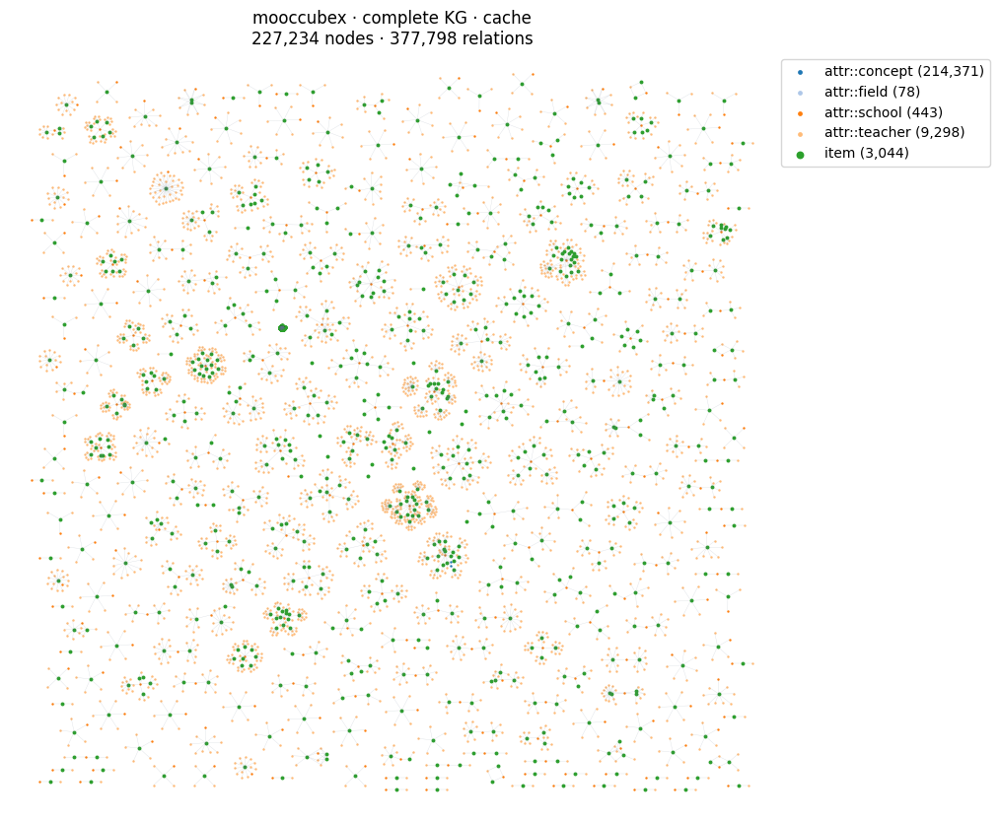

/Users/i12almuf/Code/projects/EDuRec/results/knowledge_graphs/mooccubex_cache_full.png


/Users/i12almuf/Code/projects/EDuRec/results/knowledge_graphs/mooccubex_cache_full.html


In [7]:
for name in DATASETS:
    try:
        view = load_graph_view(name, source=SOURCE, allow_download=ALLOW_DOWNLOAD)
    except (FileNotFoundError, RuntimeError) as error:
        print(f"Skipping {name}: {error}")
        continue
    graph = full_graph(view)
    if GENERATE_FULL:
        draw_graph(
            graph,
            f"{name} · complete KG · {view.source}",
            OUTPUT_DIR / f"{name}_{view.source}_full.png",
        )
    if SUBSET_MAX_NODES is not None:
        subset = sample_subgraph(graph, max_nodes=SUBSET_MAX_NODES, seed=SEED)
        draw_graph(
            subset,
            f"{name} · subset · {view.source}",
            OUTPUT_DIR / f"{name}_{view.source}_subset.png",
        )
        del subset
    del graph, view

## Optional: relations of one item

Enable by setting `FOCUS_DATASET`. Search by title or original ID, then set
`FOCUS_ITEM_ID` and rerun. Two hops show the item, its attributes, and other items
sharing those attributes. Increase `FOCUS_HOPS` to explore further; this is a
local neighborhood, not the complete graph. No neighbors are sampled.
This view also generates PNG and interactive HTML. Degree values refer to the
displayed neighborhood. Full views can require substantial browser memory.


In [8]:
FOCUS_DATASET: str | None = None  # Set, for example, "mooccubex" to enable this view.
FOCUS_ITEM_ID: str | int | None = None  # Original item ID; leave None to search first.
FOCUS_QUERY = ""  # Part of a title or ID.
FOCUS_HOPS = 2  # item -> attribute -> other items; no neighbor/node limits.

if FOCUS_DATASET is not None:
    view = load_graph_view(FOCUS_DATASET, source=SOURCE, allow_download=ALLOW_DOWNLOAD)
    if FOCUS_ITEM_ID is None:
        display(item_catalog(view, query=FOCUS_QUERY))
        print("Set FOCUS_ITEM_ID to one of these IDs and rerun this cell.")
    else:
        if not isinstance(FOCUS_HOPS, int) or FOCUS_HOPS < 0:
            raise ValueError("FOCUS_HOPS must be a nonnegative integer.")
        matches = [
            index
            for item, index in view.item_id_map.items()
            if str(item) == str(FOCUS_ITEM_ID)
        ]
        if not matches:
            raise ValueError(f"Unknown item ID: {FOCUS_ITEM_ID}")
        graph = full_graph(view)
        focus = ("item", matches[0])
        neighborhood = nx.ego_graph(graph, focus, radius=FOCUS_HOPS)
        draw_graph(
            neighborhood,
            f"{FOCUS_DATASET} · item {FOCUS_ITEM_ID} · {FOCUS_HOPS} hops · {view.source}",
            OUTPUT_DIR / f"{FOCUS_DATASET}_{view.source}_item.png",
            focus=focus,
        )
        connected_items = {index for kind, index in neighborhood if kind == "item"}
        catalog = item_catalog(view, limit=None)
        display(catalog.loc[catalog["node_index"].isin(connected_items)])
        del graph, neighborhood
    del view